
# RQ26 — Which individual Top-K models should advance toward deployment?

## Scientific question

**For each supervised benchmark endpoint, which individual `representation × learner` strategies have the strongest multi-dimensional evidence to advance into the final deployment/ensemble stage?**

RQ26 does **not** train models and does **not** create another scalar leaderboard.

It consolidates five evidence dimensions already established by previous RQs:

1. **performance** — mean / median MCC across the full `R×S` surface;
2. **strict generalization** — `R30/S30`, `S30`, and `R30` performance;
3. **robustness** — worst-case MCC, rank consistency, regret, and R/S/interaction sensitivity;
4. **finite-test uncertainty context** — targeted paired-bootstrap evidence from scientific RQ19;
5. **compute** — cell-wise Pareto frequency, near-best frequency, and downstream runtime from scientific RQ23.

The output is a **small individual-model portfolio per task**, intended to become the candidate pool for RQ27 ensembles. The portfolio may contain fewer than four members when the real benchmark does not support four defensible individual candidates.

### Canonical Top-K

RQ26 freezes a **maximum** portfolio size:

\[
K_{\max}=4
\]

and a minimum ensembleable portfolio size:

\[
K_{\min}=2.
\]

A task receives fewer than four candidates when additional strategies are neither operational role winners nor within the pre-defined `0.02 MCC` competitive band. This prevents weak `ordered_fill` models from being promoted merely to satisfy a fixed K.

For a task with `K` selected members, RQ27 evaluates all non-singleton subsets:

\[
N_{ens}=2^K-K-1.
\]

Thus `K=2`, `K=3`, and `K=4` imply 1, 4, and 11 candidate ensembles respectively.



## Selection contract

RQ17 already showed that “winning” is multidimensional. RQ26 therefore selects a **portfolio of role winners**, not the four highest values of one score.

### Four primary roles

For each task:

**1. Performance leader**

Maximize mean MCC across the 16 `R×S` cells, then worst-case MCC.

**2. Worst-case robustness leader**

Maximize minimum MCC across the full surface, then mean MCC.

**3. Joint-strict leader**

Maximize MCC at `R30/S30`, then remote (`S30`) and strict-R (`R30`) performance.

**4. Compute-aware competitive leader**

First restrict to strategies whose mean MCC is within `0.02` of the task-best mean MCC. Inside that competitive pool:

1. maximize cell-wise Pareto frequency;
2. maximize near-best frequency;
3. minimize median downstream runtime;
4. maximize mean MCC.

The `0.02 MCC` value is the same descriptive near-best tolerance used in the completed compute analysis. It is **not an equivalence margin**.

### Deduplication and fallback

Primary role winners can coincide. RQ26 therefore adds unique fallback winners, in this order:

1. rank-consistency leader;
2. lowest-regret leader;
3. remote-homology leader;
4. strict-R leader;
5. least interaction-sensitive **competitive** strategy;
6. remaining strategies ordered by mean MCC, worst-case MCC, mean regret, and runtime.

Selection stops at four unique strategies.

### Eligibility guardrail

A model can enter the final RQ26 portfolio only if at least one of the following is true:

1. it wins an explicit operational role; or
2. its mean MCC lies within `0.02` of the task-best mean MCC.

The notebook **does not force `K=4`** by adding weaker models with no operational role. If fewer than four models satisfy the evidence contract, the portfolio is intentionally smaller.

Only if fewer than two candidates survive—which would prevent any ensemble test—does the notebook add the next-best strategy as a clearly labeled `minimum_ensembleability_fill`. This is a technical fallback and is reported separately.

### Uncertainty is a guardrail, not a universal score

Scientific RQ19 intentionally bootstrapped **targeted principal contrasts**, not every possible model pair. Consequently:

- strategies with targeted uncertainty evidence receive that context;
- strategies without a targeted bootstrap contrast are labeled `not_targeted`;
- absence of targeted bootstrap evidence is **never scored as poor uncertainty**;
- overlapping-zero intervals are not treated as equivalence;
- VAL receives an explicit task-level finite-test uncertainty warning.

This prevents uneven bootstrap coverage from biasing the Top-K ranking.



## Deployment interpretation guardrail

RQ26 selects candidates **for every supervised benchmark task** because the final product architecture has not yet been frozen.

This does **not** imply that all seven benchmark tasks become production endpoints.

In particular, `global_easy`, `global_hard`, and `global_mixed` remain distinct benchmark formulations until RQ28 decides which global formulation, if any, becomes the deployed global classifier.

Thus:

> **RQ26 selects model candidates; RQ28 selects product architecture.**

The Top-K selection is a retrospective synthesis of the completed outer-test benchmark. It is not presented as a new unbiased model-selection/test split.


In [1]:

from pathlib import Path
import json
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 400)
pd.set_option("display.width", 260)
pd.set_option("display.max_rows", 400)

MAX_K = 4
MIN_K = 2
COMPETITIVE_GAP = 0.02

TASK_ORDER = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
    "multiclass_clean",
]

REP_ORDER = [
    "roxy_48",
    "onehot_1024",
    "esm2_t6_8m",
    "esm2_t30_150m",
]

ALG_ORDER = ["KNN", "LR", "MLP", "RF", "XGB"]

REP_LABEL = {
    "roxy_48": "Roxy",
    "onehot_1024": "One-hot",
    "esm2_t6_8m": "ESM2-T6",
    "esm2_t30_150m": "ESM2-T30",
}


def find_project_root(start=None):
    explicit = os.environ.get("PHAGELYSCLASS_ROOT")
    if explicit:
        root = Path(explicit).expanduser().resolve()
        if (root / "results/analysis_supervised/stage12a/supervised_master_results.tsv").is_file():
            return root
        raise FileNotFoundError(
            f"PHAGELYSCLASS_ROOT does not contain the frozen Stage12A master: {root}"
        )

    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_supervised/stage12a/supervised_master_results.tsv").is_file()
            and (candidate / "results/analysis_supervised/notebook_cache/rq17_robustness_synthesis").is_dir()
        ):
            return candidate

    raise FileNotFoundError(
        "Could not locate the PhageLysClass project root. "
        "Set PHAGELYSCLASS_ROOT or execute from inside the project."
    )


ROOT = find_project_root()

SUP_STAGE12A = ROOT / "results/analysis_supervised/stage12a"
SUP_CACHE = ROOT / "results/analysis_supervised/notebook_cache"

# Scientific RQ17 robustness synthesis (new canonical roadmap RQ17).
ROBUST_CACHE = SUP_CACHE / "rq17_robustness_synthesis"

# Scientific RQ21 joint-strictness analysis.
RQ21_CACHE = SUP_CACHE / "rq21_joint_RxS_trajectories"

# Scientific RQ19 bootstrap uncertainty still lives under the legacy rq17 cache path.
BOOT_CACHE = ROOT / "results/analysis_bootstrap/rq17"

# Scientific RQ23 compute/performance still lives under the legacy rq18 cache path.
COMPUTE_CACHE = ROOT / "results/analysis_compute/rq18"

RQ26_OUT = ROOT / "results/analysis_deployment/rq26"
FIG_DIR = RQ26_OUT / "figures"
RQ26_OUT.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("RQ26_OUT:", RQ26_OUT)
print("MAX_K:", MAX_K)
print("MIN_K:", MIN_K)
print("No training, prediction regeneration, bootstrap, or ensemble optimization is performed.")


ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
RQ26_OUT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_deployment/rq26
MAX_K: 4
MIN_K: 2
No training, prediction regeneration, bootstrap, or ensemble optimization is performed.


## 1. Real-project preflight

In [2]:

PATHS = {
    "supervised_master": SUP_STAGE12A / "supervised_master_results.tsv",
    "robustness_profiles": ROBUST_CACHE / "rq17_surface_robustness_profiles.tsv",
    "rq21_profiles": RQ21_CACHE / "rq21_surface_mixed_trajectory_profiles.tsv",
    "compute_cells": COMPUTE_CACHE / "rq18_supervised_efficiency_cells.tsv",
    "bootstrap_representation": BOOT_CACHE / "rq17_supervised_representation_uncertainty_summary.tsv",
    "bootstrap_algorithm": BOOT_CACHE / "rq17_supervised_algorithm_uncertainty_summary.tsv",
    "bootstrap_VAL": BOOT_CACHE / "rq17_VAL_uncertainty_summary.tsv",
}

preflight = pd.DataFrame([
    {
        "artifact": name,
        "path": str(path),
        "exists": path.is_file(),
    }
    for name, path in PATHS.items()
])

display(preflight)

missing = preflight.loc[~preflight["exists"], ["artifact", "path"]]
if len(missing):
    raise FileNotFoundError(
        "RQ26 requires completed upstream artifacts:\n"
        + missing.to_string(index=False)
    )

print("REAL_PROJECT_PREFLIGHT_OK")


,artifact,path,exists
0,supervised_master,/home/david/Desktop/colabs/inta_project/phagel...,True
1,robustness_profiles,/home/david/Desktop/colabs/inta_project/phagel...,True
2,rq21_profiles,/home/david/Desktop/colabs/inta_project/phagel...,True
3,compute_cells,/home/david/Desktop/colabs/inta_project/phagel...,True
4,bootstrap_representation,/home/david/Desktop/colabs/inta_project/phagel...,True
5,bootstrap_algorithm,/home/david/Desktop/colabs/inta_project/phagel...,True
6,bootstrap_VAL,/home/david/Desktop/colabs/inta_project/phagel...,True


REAL_PROJECT_PREFLIGHT_OK


## 2. Load frozen benchmark and completed evidence tables

In [3]:

master = pd.read_csv(PATHS["supervised_master"], sep="\t", low_memory=False)
robust = pd.read_csv(PATHS["robustness_profiles"], sep="\t", low_memory=False)
joint = pd.read_csv(PATHS["rq21_profiles"], sep="\t", low_memory=False)
compute_cells = pd.read_csv(PATHS["compute_cells"], sep="\t", low_memory=False)

rep_unc = pd.read_csv(PATHS["bootstrap_representation"], sep="\t", low_memory=False)
alg_unc = pd.read_csv(PATHS["bootstrap_algorithm"], sep="\t", low_memory=False)
val_unc = pd.read_csv(PATHS["bootstrap_VAL"], sep="\t", low_memory=False)

required_master = {"task", "R", "S", "representation", "algorithm", "mcc"}
required_robust = {
    "task", "representation", "algorithm",
    "mean_mcc", "median_mcc", "worst_mcc", "peak_mcc",
    "surface_range", "strict_mcc_R30S30",
    "remote_S30_mean_mcc", "strict_R30_mean_mcc",
    "mean_rank", "worst_rank", "mean_regret", "worst_regret",
    "R_sensitivity_abs_median", "S_sensitivity_abs_median",
    "interaction_rms", "strict_retention_fraction",
}
required_joint = {
    "task", "representation", "algorithm",
    "strict_retention_fraction",
    "diag_net_delta",
    "median_abs_allocation_delta",
}
required_compute = {
    "task", "representation", "algorithm",
    "pareto_efficient", "near_best_0p02",
    "downstream_runtime_seconds",
}

for name, df, req in [
    ("master", master, required_master),
    ("robust", robust, required_robust),
    ("joint", joint, required_joint),
    ("compute_cells", compute_cells, required_compute),
]:
    missing = req - set(df.columns)
    if missing:
        raise KeyError(f"{name} missing required columns: {sorted(missing)}")

assert len(master) == 2240, len(master)
assert len(robust) == 140, len(robust)
assert len(joint) == 140, len(joint)

assert master.groupby(["task", "representation", "algorithm"]).size().eq(16).all()
assert robust.groupby("task").size().eq(20).all()
assert joint.groupby("task").size().eq(20).all()

print("Master rows:", len(master))
print("Robustness profiles:", len(robust))
print("Joint-strictness profiles:", len(joint))
print("Compute cells:", len(compute_cells))
print("Representation uncertainty rows:", len(rep_unc))
print("Algorithm uncertainty rows:", len(alg_unc))
print("VAL uncertainty rows:", len(val_unc))


Master rows: 2240
Robustness profiles: 140
Joint-strictness profiles: 140
Compute cells: 2240
Representation uncertainty rows: 14
Algorithm uncertainty rows: 14
VAL uncertainty rows: 12


## 3. Aggregate task-specific compute evidence

In [4]:

compute = (
    compute_cells.groupby(
        ["task", "representation", "algorithm"],
        as_index=False,
    )
    .agg(
        pareto_rate=("pareto_efficient", "mean"),
        near_best_rate=("near_best_0p02", "mean"),
        median_runtime_s=("downstream_runtime_seconds", "median"),
        q90_runtime_s=("downstream_runtime_seconds", lambda x: x.quantile(0.90)),
    )
)

if "mcc_gap_to_cell_best" in compute_cells.columns:
    gap = (
        compute_cells.groupby(
            ["task", "representation", "algorithm"],
            as_index=False,
        )
        .agg(
            median_gap_to_cell_best=("mcc_gap_to_cell_best", "median"),
            worst_gap_to_cell_best=("mcc_gap_to_cell_best", "max"),
        )
    )
    compute = compute.merge(
        gap,
        on=["task", "representation", "algorithm"],
        validate="one_to_one",
    )
else:
    compute["median_gap_to_cell_best"] = np.nan
    compute["worst_gap_to_cell_best"] = np.nan

assert len(compute) == 140
assert compute[
    ["pareto_rate", "near_best_rate", "median_runtime_s"]
].notna().all().all()

display(
    compute.sort_values(
        ["task", "near_best_rate", "pareto_rate", "median_runtime_s"],
        ascending=[True, False, False, True],
    ).head(30)
)


,task,representation,algorithm,pareto_rate,near_best_rate,median_runtime_s,q90_runtime_s,median_gap_to_cell_best,worst_gap_to_cell_best
0,global_easy,esm2_t30_150m,KNN,1.0000,1.0000,2.857057,6.007964,0.000000,0.012738
2,global_easy,esm2_t30_150m,MLP,0.3750,0.8750,78.744082,130.800458,0.003133,0.020904
4,global_easy,esm2_t30_150m,XGB,0.1250,0.8750,94.989578,132.072724,0.011294,0.025633
15,global_easy,roxy_48,KNN,1.0000,0.0000,1.843818,3.673646,0.281030,0.318357
5,global_easy,esm2_t6_8m,KNN,0.8125,0.0000,2.380511,5.435327,0.118306,0.134926
16,global_easy,roxy_48,LR,0.2500,0.0000,3.189922,5.918811,0.454392,0.487236
19,global_easy,roxy_48,XGB,0.0625,0.0000,5.464495,9.642683,0.239903,0.298679
10,global_easy,onehot_1024,KNN,0.0000,0.0000,5.328307,13.416964,0.430239,0.548412
1,global_easy,esm2_t30_150m,LR,0.0000,0.0000,11.152947,12.043655,0.038935,0.072587
18,global_easy,roxy_48,RF,0.0000,0.0000,11.894483,19.338090,0.301727,0.350561


## 4. Build the complete deployment-candidate evidence profile

In [5]:

MERGE_KEYS = ["task", "representation", "algorithm"]

joint_keep = joint[
    [
        *MERGE_KEYS,
        "strict_retention_fraction",
        "diag_net_delta",
        "median_same_J_range",
        "median_abs_allocation_delta",
        "fraction_R_heavy_worse",
        "median_joint_excess_over_additive",
    ]
].copy()

# Both RQ17 and RQ21 carry the same strict-corner retention ratio.
# Validate agreement explicitly and retain RQ17 as the canonical field.
retention_check = (
    robust[
        MERGE_KEYS + ["strict_retention_fraction"]
    ]
    .merge(
        joint[
            MERGE_KEYS + ["strict_retention_fraction"]
        ],
        on=MERGE_KEYS,
        how="inner",
        validate="one_to_one",
        suffixes=("_rq17", "_rq21"),
    )
)

assert len(retention_check) == 140

retention_diff = (
    retention_check["strict_retention_fraction_rq17"]
    - retention_check["strict_retention_fraction_rq21"]
).abs()

max_retention_diff = float(retention_diff.max())
print("Max RQ17↔RQ21 strict-retention difference:", max_retention_diff)

if max_retention_diff > 1e-10:
    bad = retention_check.loc[
        retention_diff.gt(1e-10),
        MERGE_KEYS
        + [
            "strict_retention_fraction_rq17",
            "strict_retention_fraction_rq21",
        ],
    ]
    raise AssertionError(
        "RQ17 and RQ21 disagree on strict_retention_fraction. "
        "Inspect upstream caches before deployment selection.\n"
        + bad.head(20).to_string(index=False)
    )

# Avoid duplicate payload column before the real merge.
joint_keep = joint_keep.drop(columns=["strict_retention_fraction"])

# Guard against any other accidental payload collisions.
robust_payload = set(robust.columns) - set(MERGE_KEYS)
joint_payload = set(joint_keep.columns) - set(MERGE_KEYS)
unexpected_overlap = sorted(robust_payload & joint_payload)
if unexpected_overlap:
    raise KeyError(
        "Unexpected RQ17/RQ21 payload-column collision: "
        f"{unexpected_overlap}"
    )

profile = (
    robust
    .merge(
        compute,
        on=MERGE_KEYS,
        how="left",
        validate="one_to_one",
    )
    .merge(
        joint_keep,
        on=MERGE_KEYS,
        how="left",
        validate="one_to_one",
    )
)

profile["strategy_id"] = (
    profile["representation"].astype(str)
    + " + "
    + profile["algorithm"].astype(str)
)

assert len(profile) == 140
assert profile.groupby("task").size().eq(20).all()
assert "strict_retention_fraction" in profile.columns
assert not any(
    c.startswith("strict_retention_fraction_")
    for c in profile.columns
)
assert profile[
    [
        "mean_mcc", "worst_mcc", "strict_mcc_R30S30",
        "mean_rank", "mean_regret",
        "pareto_rate", "near_best_rate", "median_runtime_s",
        "strict_retention_fraction",
    ]
].notna().all().all()

print("RQ17_RQ21_MERGE_SCHEMA_OK")

display(
    profile[
        [
            "task", "strategy_id",
            "mean_mcc", "worst_mcc", "strict_mcc_R30S30",
            "mean_rank", "mean_regret",
            "pareto_rate", "near_best_rate", "median_runtime_s",
            "strict_retention_fraction",
        ]
    ].head()
)


Max RQ17↔RQ21 strict-retention difference: 0.0
RQ17_RQ21_MERGE_SCHEMA_OK


,task,strategy_id,mean_mcc,worst_mcc,strict_mcc_R30S30,mean_rank,mean_regret,pareto_rate,near_best_rate,median_runtime_s,strict_retention_fraction
0,global_easy,roxy_48 + LR,0.482347,0.449463,0.473778,16.6250,0.448299,0.2500,0.0,3.189922,0.926002
1,global_easy,roxy_48 + RF,0.630261,0.537101,0.537101,13.9375,0.300384,0.0000,0.0,11.894483,0.758050
2,global_easy,roxy_48 + KNN,0.653812,0.569305,0.569305,12.8750,0.276834,1.0000,0.0,1.843818,0.738440
3,global_easy,roxy_48 + XGB,0.690156,0.591684,0.640564,11.1250,0.240490,0.0625,0.0,5.464495,0.828963
4,global_easy,roxy_48 + MLP,0.670811,0.597200,0.633651,12.1250,0.259835,0.0000,0.0,100.686897,0.818500



## 5. Attach targeted uncertainty context without converting it into a score

The bootstrap summaries are intentionally targeted.

RQ26 records whether a candidate participates in a directly relevant uncertainty family:

- `T30_minus_T6`
- `T30_minus_Roxy`
- `MLP_minus_LR` inside T30
- `MLP_minus_XGB` inside T30

For VAL, the task-level MCC CI-width/support summary is attached to every candidate because finite-test resolution is a property of that evidence-limited endpoint.

The resulting fields are **context labels**, not ranking penalties.


In [6]:

def fmt_unc_row(row, prefix):
    parts = [prefix]
    for c in [
        "median_point_delta",
        "median_ci_width",
        "fraction_resolved_positive",
        "fraction_resolved_negative",
        "fraction_overlaps_zero",
    ]:
        if c in row.index and pd.notna(row[c]):
            parts.append(f"{c}={float(row[c]):.3f}")
    return ";".join(parts)


def uncertainty_context_for_strategy(task, representation, algorithm):
    contexts = []

    # Representation contrasts.
    relevant_rep_contrasts = []
    if representation == "esm2_t30_150m":
        relevant_rep_contrasts = ["T30_minus_T6", "T30_minus_Roxy"]
    elif representation == "esm2_t6_8m":
        relevant_rep_contrasts = ["T30_minus_T6"]
    elif representation == "roxy_48":
        relevant_rep_contrasts = ["T30_minus_Roxy"]

    if {"contrast", "task"} <= set(rep_unc.columns):
        rows = rep_unc[
            rep_unc["task"].eq(task)
            & rep_unc["contrast"].isin(relevant_rep_contrasts)
        ]
        for _, row in rows.iterrows():
            contexts.append(fmt_unc_row(row, f"rep:{row['contrast']}"))

    # Algorithm contrasts were bootstrapped only inside T30.
    relevant_alg_contrasts = []
    if representation == "esm2_t30_150m":
        if algorithm in {"MLP", "LR"}:
            relevant_alg_contrasts.append("MLP_minus_LR")
        if algorithm in {"MLP", "XGB"}:
            relevant_alg_contrasts.append("MLP_minus_XGB")

    if {"contrast", "task"} <= set(alg_unc.columns):
        rows = alg_unc[
            alg_unc["task"].eq(task)
            & alg_unc["contrast"].isin(relevant_alg_contrasts)
        ]
        for _, row in rows.iterrows():
            contexts.append(fmt_unc_row(row, f"alg:{row['contrast']}"))

    # VAL absolute uncertainty is task-level, not candidate-specific.
    if task == "subtype_val" and len(val_unc):
        v = val_unc.copy()
        if "metric" in v.columns:
            v = v[v["metric"].eq("mcc")]
        if len(v):
            med_ci = (
                float(v["median_ci_width"].median())
                if "median_ci_width" in v.columns else np.nan
            )
            med_pos = (
                float(v["median_n_positive"].median())
                if "median_n_positive" in v.columns else np.nan
            )
            contexts.append(
                f"VAL_task_level:median_MCC_CI_width={med_ci:.3f};"
                f"median_positive_support={med_pos:.1f}"
            )

    if not contexts:
        return "not_targeted", 0

    return " | ".join(contexts), len(contexts)


unc_rows = []
for row in profile.itertuples(index=False):
    text, n = uncertainty_context_for_strategy(
        row.task, row.representation, row.algorithm
    )
    unc_rows.append({
        "task": row.task,
        "representation": row.representation,
        "algorithm": row.algorithm,
        "targeted_uncertainty_context": text,
        "n_targeted_uncertainty_contexts": n,
    })

unc_context = pd.DataFrame(unc_rows)

profile = profile.merge(
    unc_context,
    on=["task", "representation", "algorithm"],
    how="left",
    validate="one_to_one",
)

display(
    profile[
        [
            "task", "strategy_id",
            "n_targeted_uncertainty_contexts",
            "targeted_uncertainty_context",
        ]
    ].head(30)
)


,task,strategy_id,n_targeted_uncertainty_contexts,targeted_uncertainty_context
0,global_easy,roxy_48 + LR,1,rep:T30_minus_Roxy;median_point_delta=0.241;me...
1,global_easy,roxy_48 + RF,1,rep:T30_minus_Roxy;median_point_delta=0.241;me...
2,global_easy,roxy_48 + KNN,1,rep:T30_minus_Roxy;median_point_delta=0.241;me...
3,global_easy,roxy_48 + XGB,1,rep:T30_minus_Roxy;median_point_delta=0.241;me...
4,global_easy,roxy_48 + MLP,1,rep:T30_minus_Roxy;median_point_delta=0.241;me...
5,global_easy,onehot_1024 + LR,0,not_targeted
6,global_easy,onehot_1024 + RF,0,not_targeted
7,global_easy,onehot_1024 + KNN,0,not_targeted
8,global_easy,onehot_1024 + XGB,0,not_targeted
9,global_easy,onehot_1024 + MLP,0,not_targeted


## 6. Define operational role winners

In [7]:

def pick_one(df, sort_cols, ascending):
    return (
        df.sort_values(
            sort_cols,
            ascending=ascending,
            kind="mergesort",
        )
        .iloc[0]
    )


role_rows = []

for task, grp in profile.groupby("task", sort=False):
    best_mean = float(grp["mean_mcc"].max())
    competitive = grp[
        grp["mean_mcc"].ge(best_mean - COMPETITIVE_GAP - 1e-12)
    ].copy()

    roles = [
        (
            "performance_leader",
            grp,
            ["mean_mcc", "worst_mcc", "mean_regret", "median_runtime_s"],
            [False, False, True, True],
        ),
        (
            "worst_case_leader",
            grp,
            ["worst_mcc", "mean_mcc", "mean_regret", "median_runtime_s"],
            [False, False, True, True],
        ),
        (
            "joint_strict_leader",
            grp,
            [
                "strict_mcc_R30S30",
                "remote_S30_mean_mcc",
                "strict_R30_mean_mcc",
                "mean_mcc",
            ],
            [False, False, False, False],
        ),
        (
            "compute_aware_competitive_leader",
            competitive,
            [
                "pareto_rate",
                "near_best_rate",
                "median_runtime_s",
                "mean_mcc",
            ],
            [False, False, True, False],
        ),
        (
            "rank_consistency_leader",
            grp,
            ["mean_rank", "mean_regret", "worst_rank", "mean_mcc"],
            [True, True, True, False],
        ),
        (
            "lowest_regret_leader",
            grp,
            ["mean_regret", "mean_rank", "worst_regret", "mean_mcc"],
            [True, True, True, False],
        ),
        (
            "remote_homology_leader",
            grp,
            ["remote_S30_mean_mcc", "worst_mcc", "mean_mcc"],
            [False, False, False],
        ),
        (
            "strict_R_leader",
            grp,
            ["strict_R30_mean_mcc", "worst_mcc", "mean_mcc"],
            [False, False, False],
        ),
        (
            "least_interaction_sensitive_competitive",
            competitive,
            ["interaction_rms", "mean_mcc", "worst_mcc"],
            [True, False, False],
        ),
    ]

    for role, pool, sort_cols, ascending in roles:
        winner = pick_one(pool, sort_cols, ascending)
        role_rows.append({
            "task": task,
            "role": role,
            "strategy_id": winner["strategy_id"],
            "representation": winner["representation"],
            "algorithm": winner["algorithm"],
            "mean_mcc": winner["mean_mcc"],
            "worst_mcc": winner["worst_mcc"],
            "strict_mcc_R30S30": winner["strict_mcc_R30S30"],
            "mean_rank": winner["mean_rank"],
            "mean_regret": winner["mean_regret"],
            "pareto_rate": winner["pareto_rate"],
            "near_best_rate": winner["near_best_rate"],
            "median_runtime_s": winner["median_runtime_s"],
            "competitive_pool_size": len(pool),
        })

role_winners = pd.DataFrame(role_rows)

display(
    role_winners.pivot(
        index="role",
        columns="task",
        values="strategy_id",
    ).reindex(columns=TASK_ORDER)
)


task,global_easy,global_hard,global_mixed,subtype_endolysin,subtype_depolymerase,subtype_val,multiclass_clean
role,,,,,,,
compute_aware_competitive_leader,esm2_t30_150m + KNN,esm2_t6_8m + KNN,esm2_t30_150m + KNN,esm2_t30_150m + KNN,esm2_t6_8m + KNN,esm2_t30_150m + MLP,esm2_t30_150m + KNN
joint_strict_leader,esm2_t30_150m + KNN,esm2_t30_150m + RF,esm2_t30_150m + MLP,esm2_t30_150m + KNN,esm2_t30_150m + KNN,esm2_t30_150m + LR,esm2_t30_150m + MLP
least_interaction_sensitive_competitive,esm2_t30_150m + XGB,esm2_t30_150m + RF,esm2_t30_150m + KNN,esm2_t30_150m + MLP,esm2_t30_150m + MLP,esm2_t30_150m + MLP,esm2_t30_150m + LR
lowest_regret_leader,esm2_t30_150m + KNN,esm2_t30_150m + RF,esm2_t30_150m + KNN,esm2_t30_150m + KNN,esm2_t30_150m + MLP,esm2_t30_150m + MLP,esm2_t30_150m + MLP
performance_leader,esm2_t30_150m + KNN,esm2_t30_150m + RF,esm2_t30_150m + KNN,esm2_t30_150m + KNN,esm2_t30_150m + MLP,esm2_t30_150m + MLP,esm2_t30_150m + MLP
rank_consistency_leader,esm2_t30_150m + KNN,esm2_t30_150m + RF,esm2_t30_150m + KNN,esm2_t30_150m + KNN,esm2_t30_150m + MLP,esm2_t30_150m + MLP,esm2_t30_150m + KNN
remote_homology_leader,esm2_t30_150m + KNN,esm2_t30_150m + RF,esm2_t30_150m + MLP,esm2_t30_150m + KNN,esm2_t30_150m + MLP,esm2_t30_150m + MLP,esm2_t30_150m + XGB
strict_R_leader,esm2_t30_150m + KNN,esm2_t30_150m + RF,esm2_t30_150m + KNN,esm2_t30_150m + MLP,esm2_t6_8m + MLP,esm2_t30_150m + LR,esm2_t30_150m + KNN
worst_case_leader,esm2_t30_150m + KNN,esm2_t30_150m + RF,esm2_t30_150m + KNN,esm2_t30_150m + XGB,esm2_t30_150m + MLP,esm2_t30_150m + MLP,esm2_t30_150m + XGB



## 7. Select the smallest defensible individual portfolio, up to K=4

The selection procedure preserves the operational-role logic but no longer forces four candidates.

A strategy is eligible when:

- it wins at least one explicit role; **or**
- it is within `0.02 MCC` of the task-best mean MCC.

Primary role winners enter first, followed by unique fallback-role winners. Competitive non-role strategies can then fill remaining slots up to `K_max=4`.

No non-competitive, role-free model is promoted merely to satisfy a fixed K.


In [8]:

PRIMARY_ROLE_ORDER = [
    "performance_leader",
    "worst_case_leader",
    "joint_strict_leader",
    "compute_aware_competitive_leader",
]

FALLBACK_ROLE_ORDER = [
    "rank_consistency_leader",
    "lowest_regret_leader",
    "remote_homology_leader",
    "strict_R_leader",
    "least_interaction_sensitive_competitive",
]


def strategy_key(row):
    return (str(row["representation"]), str(row["algorithm"]))


selected_rows = []
selection_audit_rows = []

for task, grp in profile.groupby("task", sort=False):
    grp = grp.copy()
    task_roles = role_winners[role_winners["task"].eq(task)].copy()

    best_mean = float(grp["mean_mcc"].max())
    grp["mean_gap_to_best"] = best_mean - grp["mean_mcc"]
    grp["mean_competitive_0p02"] = grp["mean_gap_to_best"].le(
        COMPETITIVE_GAP + 1e-12
    )

    role_map = (
        task_roles.groupby("strategy_id")["role"]
        .apply(lambda x: ",".join(x))
        .to_dict()
    )
    grp["all_roles_won_tmp"] = grp["strategy_id"].map(role_map).fillna("")
    grp["wins_any_role"] = grp["all_roles_won_tmp"].ne("")
    grp["portfolio_eligible"] = (
        grp["wins_any_role"] | grp["mean_competitive_0p02"]
    )

    selected = []
    selected_keys = set()

    def add_candidate(strategy_id, reason, eligibility_basis):
        row = grp[grp["strategy_id"].eq(strategy_id)]
        if len(row) != 1:
            raise RuntimeError(
                f"Expected one profile row for {task} / {strategy_id}, "
                f"found {len(row)}"
            )
        row = row.iloc[0]
        key = strategy_key(row)
        if key in selected_keys:
            return False
        selected_keys.add(key)
        selected.append((row, reason, eligibility_basis))
        return True

    # 1) Primary operational roles.
    for role in PRIMARY_ROLE_ORDER:
        winner = task_roles.loc[
            task_roles["role"].eq(role), "strategy_id"
        ].iloc[0]
        row = grp[grp["strategy_id"].eq(winner)].iloc[0]
        basis = (
            f"role:{role}"
            + ("+mean_competitive" if row["mean_competitive_0p02"] else "")
        )
        add_candidate(winner, role, basis)
        if len(selected) >= MAX_K:
            break

    # 2) Fallback operational roles.
    if len(selected) < MAX_K:
        for role in FALLBACK_ROLE_ORDER:
            winner = task_roles.loc[
                task_roles["role"].eq(role), "strategy_id"
            ].iloc[0]
            row = grp[grp["strategy_id"].eq(winner)].iloc[0]
            basis = (
                f"role:{role}"
                + ("+mean_competitive" if row["mean_competitive_0p02"] else "")
            )
            add_candidate(winner, role, basis)
            if len(selected) >= MAX_K:
                break

    # 3) Competitive non-role fill only.
    if len(selected) < MAX_K:
        competitive_remainder = grp[
            grp["mean_competitive_0p02"]
        ].sort_values(
            ["mean_mcc", "worst_mcc", "mean_regret", "median_runtime_s"],
            ascending=[False, False, True, True],
            kind="mergesort",
        )

        for _, row in competitive_remainder.iterrows():
            add_candidate(
                row["strategy_id"],
                "competitive_fill",
                "mean_competitive",
            )
            if len(selected) >= MAX_K:
                break

    # 4) Technical fallback only if fewer than two survive.
    if len(selected) < MIN_K:
        remainder = grp.sort_values(
            ["mean_mcc", "worst_mcc", "mean_regret", "median_runtime_s"],
            ascending=[False, False, True, True],
            kind="mergesort",
        )

        for _, row in remainder.iterrows():
            add_candidate(
                row["strategy_id"],
                "minimum_ensembleability_fill",
                "technical_MIN_K_fallback",
            )
            if len(selected) >= MIN_K:
                break

    if not (MIN_K <= len(selected) <= MAX_K):
        raise RuntimeError(
            f"{task}: selected {len(selected)} candidates; "
            f"expected {MIN_K}..{MAX_K}"
        )

    selected_ids = {row["strategy_id"] for row, _, _ in selected}

    for _, row in grp.iterrows():
        selection_audit_rows.append({
            "task": task,
            "strategy_id": row["strategy_id"],
            "representation": row["representation"],
            "algorithm": row["algorithm"],
            "mean_mcc": row["mean_mcc"],
            "mean_gap_to_best": row["mean_gap_to_best"],
            "mean_competitive_0p02": bool(row["mean_competitive_0p02"]),
            "wins_any_role": bool(row["wins_any_role"]),
            "all_roles_won": row["all_roles_won_tmp"],
            "portfolio_eligible": bool(row["portfolio_eligible"]),
            "selected": row["strategy_id"] in selected_ids,
        })

    for rank, (row, reason, basis) in enumerate(selected, start=1):
        rec = row.drop(
            labels=[
                "all_roles_won_tmp",
                "wins_any_role",
                "portfolio_eligible",
            ],
            errors="ignore",
        ).to_dict()

        rec.update({
            "topK_rank": rank,
            "selection_entry_reason": reason,
            "eligibility_basis": basis,
            "all_roles_won": role_map.get(row["strategy_id"], ""),
        })
        selected_rows.append(rec)

topk = pd.DataFrame(selected_rows)
selection_audit = pd.DataFrame(selection_audit_rows)

assert len(topk) >= len(TASK_ORDER) * MIN_K
assert len(topk) <= len(TASK_ORDER) * MAX_K
assert topk.groupby("task").size().between(MIN_K, MAX_K).all()
assert topk.groupby(["task", "strategy_id"]).size().eq(1).all()

selected_audit = selection_audit[selection_audit["selected"]].copy()
technical_fill_ids = set(
    topk.loc[
        topk["selection_entry_reason"].eq("minimum_ensembleability_fill"),
        ["task", "strategy_id"],
    ].itertuples(index=False, name=None)
)

for row in selected_audit.itertuples(index=False):
    if (row.task, row.strategy_id) in technical_fill_ids:
        continue
    assert row.portfolio_eligible, (
        f"Selected non-eligible candidate: {row.task} / {row.strategy_id}"
    )

print("Selected K by task:")
display(
    topk.groupby("task")
    .size()
    .rename("K")
    .reindex(TASK_ORDER)
    .to_frame()
)

display(
    topk[
        [
            "task", "topK_rank", "strategy_id",
            "selection_entry_reason", "eligibility_basis",
            "all_roles_won",
            "mean_mcc", "mean_gap_to_best",
            "worst_mcc", "strict_mcc_R30S30",
            "mean_rank", "mean_regret",
            "pareto_rate", "near_best_rate", "median_runtime_s",
            "targeted_uncertainty_context",
        ]
    ]
)


Selected K by task:


,K
task,
global_easy,3
global_hard,4
global_mixed,3
subtype_endolysin,3
subtype_depolymerase,4
subtype_val,2
multiclass_clean,4


,task,topK_rank,strategy_id,selection_entry_reason,eligibility_basis,all_roles_won,mean_mcc,mean_gap_to_best,worst_mcc,strict_mcc_R30S30,mean_rank,mean_regret,pareto_rate,near_best_rate,median_runtime_s,targeted_uncertainty_context
0,global_easy,1,esm2_t30_150m + KNN,performance_leader,role:performance_leader+mean_competitive,"performance_leader,worst_case_leader,joint_str...",0.928306,0.000000,0.883696,0.887662,1.5625,0.002340,1.0000,1.0000,2.857057,rep:T30_minus_Roxy;median_point_delta=0.241;me...
1,global_easy,2,esm2_t30_150m + XGB,least_interaction_sensitive_competitive,role:least_interaction_sensitive_competitive+m...,least_interaction_sensitive_competitive,0.919407,0.008898,0.871548,0.879389,2.6250,0.011238,0.1250,0.8750,94.989578,rep:T30_minus_Roxy;median_point_delta=0.241;me...
2,global_easy,3,esm2_t30_150m + MLP,competitive_fill,mean_competitive,,0.925064,0.003242,0.869458,0.877293,1.8125,0.005582,0.3750,0.8750,78.744082,rep:T30_minus_Roxy;median_point_delta=0.241;me...
3,global_hard,1,esm2_t30_150m + RF,performance_leader,role:performance_leader+mean_competitive,"performance_leader,worst_case_leader,joint_str...",0.939007,0.000000,0.915296,0.915296,2.7500,0.003834,0.5000,1.0000,9.318324,rep:T30_minus_Roxy;median_point_delta=0.072;me...
4,global_hard,2,esm2_t6_8m + KNN,compute_aware_competitive_leader,role:compute_aware_competitive_leader+mean_com...,compute_aware_competitive_leader,0.926669,0.012338,0.895484,0.903153,7.1875,0.016173,0.8125,0.6875,0.645913,rep:T30_minus_T6;median_point_delta=0.006;medi...
5,global_hard,3,esm2_t30_150m + XGB,competitive_fill,mean_competitive,,0.936535,0.002473,0.900904,0.900904,3.1875,0.006307,0.1250,1.0000,38.183011,rep:T30_minus_Roxy;median_point_delta=0.072;me...
6,global_hard,4,esm2_t30_150m + MLP,competitive_fill,mean_competitive,,0.932570,0.006437,0.899887,0.900689,4.7500,0.010272,0.0625,0.9375,26.048537,rep:T30_minus_Roxy;median_point_delta=0.072;me...
7,global_mixed,1,esm2_t30_150m + KNN,performance_leader,role:performance_leader+mean_competitive,"performance_leader,worst_case_leader,compute_a...",0.923514,0.000000,0.873647,0.873647,1.5000,0.002631,1.0000,1.0000,3.132747,rep:T30_minus_Roxy;median_point_delta=0.243;me...
8,global_mixed,2,esm2_t30_150m + MLP,joint_strict_leader,role:joint_strict_leader+mean_competitive,"joint_strict_leader,remote_homology_leader",0.920808,0.002706,0.864446,0.881569,1.8750,0.005337,0.3750,1.0000,107.806565,rep:T30_minus_Roxy;median_point_delta=0.243;me...
9,global_mixed,3,esm2_t30_150m + XGB,competitive_fill,mean_competitive,,0.916379,0.007134,0.867012,0.867012,2.6250,0.009766,0.1250,0.9375,97.916352,rep:T30_minus_Roxy;median_point_delta=0.243;me...



## 8. Quantify what the selected portfolio preserves

For each task we record:

- actual selected `K`;
- best mean MCC represented;
- best worst-case MCC represented;
- best strict `R30/S30` MCC represented;
- best Pareto frequency represented;
- fastest competitive model represented;
- representation and learner diversity;
- whether all primary operational role winners remain represented.

Because `K` is evidence-adaptive, portfolio size itself is informative: if only two or three strategies survive, the benchmark does not justify manufacturing a fourth standalone deployment candidate.


In [9]:

coverage_rows = []

for task, grp in profile.groupby("task", sort=False):
    sel = topk[topk["task"].eq(task)]

    best_mean = grp["mean_mcc"].max()
    best_worst = grp["worst_mcc"].max()
    best_strict = grp["strict_mcc_R30S30"].max()
    best_pareto = grp["pareto_rate"].max()

    competitive = grp[
        grp["mean_mcc"].ge(best_mean - COMPETITIVE_GAP - 1e-12)
    ]
    fastest_competitive_runtime = competitive["median_runtime_s"].min()

    primary_ids = set(
        role_winners.loc[
            role_winners["task"].eq(task)
            & role_winners["role"].isin(PRIMARY_ROLE_ORDER),
            "strategy_id",
        ]
    )

    coverage_rows.append({
        "task": task,
        "K": len(sel),
        "n_expected_RQ27_non_singleton_subsets": int(
            2 ** len(sel) - len(sel) - 1
        ),
        "n_representations": sel["representation"].nunique(),
        "n_algorithms": sel["algorithm"].nunique(),
        "n_mean_competitive_selected": int(
            sel["mean_gap_to_best"].le(COMPETITIVE_GAP + 1e-12).sum()
        ),
        "n_role_supported_selected": int(
            sel["all_roles_won"].fillna("").ne("").sum()
        ),
        "n_technical_MIN_K_fills": int(
            sel["selection_entry_reason"].eq(
                "minimum_ensembleability_fill"
            ).sum()
        ),
        "best_mean_mcc_all": best_mean,
        "best_mean_mcc_topK": sel["mean_mcc"].max(),
        "best_worst_mcc_all": best_worst,
        "best_worst_mcc_topK": sel["worst_mcc"].max(),
        "best_strict_mcc_all": best_strict,
        "best_strict_mcc_topK": sel["strict_mcc_R30S30"].max(),
        "best_pareto_rate_all": best_pareto,
        "best_pareto_rate_topK": sel["pareto_rate"].max(),
        "fastest_competitive_runtime_all": fastest_competitive_runtime,
        "fastest_topK_runtime": sel["median_runtime_s"].min(),
        "all_primary_roles_represented": primary_ids.issubset(
            set(sel["strategy_id"])
        ),
    })

portfolio_coverage = pd.DataFrame(coverage_rows)
display(portfolio_coverage)


,task,K,n_expected_RQ27_non_singleton_subsets,n_representations,n_algorithms,n_mean_competitive_selected,n_role_supported_selected,n_technical_MIN_K_fills,best_mean_mcc_all,best_mean_mcc_topK,best_worst_mcc_all,best_worst_mcc_topK,best_strict_mcc_all,best_strict_mcc_topK,best_pareto_rate_all,best_pareto_rate_topK,fastest_competitive_runtime_all,fastest_topK_runtime,all_primary_roles_represented
0,global_easy,3,4,1,3,3,2,0,0.928306,0.928306,0.883696,0.883696,0.887662,0.887662,1.0000,1.0000,2.857057,2.857057,True
1,global_hard,4,11,2,4,4,2,0,0.939007,0.939007,0.915296,0.915296,0.915296,0.915296,1.0000,0.8125,0.645913,0.645913,True
2,global_mixed,3,4,1,3,3,2,0,0.923514,0.923514,0.873647,0.873647,0.881569,0.881569,1.0000,1.0000,3.132747,3.132747,True
3,subtype_endolysin,3,4,1,3,3,3,0,0.922259,0.922259,0.863086,0.863086,0.888853,0.888853,1.0000,1.0000,2.724342,2.724342,True
4,subtype_depolymerase,4,11,2,2,3,4,0,0.919885,0.919885,0.885865,0.885865,0.930909,0.930909,1.0000,1.0000,1.924559,1.924559,True
5,subtype_val,2,1,1,2,1,2,0,0.857846,0.857846,0.754994,0.754994,0.889474,0.889474,0.8125,0.8125,27.930861,2.423669,True
6,multiclass_clean,4,11,1,4,4,4,0,0.887182,0.887182,0.836876,0.836876,0.889990,0.889990,0.9375,0.9375,0.574971,0.574971,True


## 9. Task-specific candidate tables

In [10]:

for task in TASK_ORDER:
    print("\n###", task)
    display(
        topk[topk["task"].eq(task)][
            [
                "topK_rank", "strategy_id",
                "selection_entry_reason", "all_roles_won",
                "mean_mcc", "worst_mcc",
                "strict_mcc_R30S30",
                "remote_S30_mean_mcc",
                "strict_R30_mean_mcc",
                "mean_rank", "mean_regret",
                "R_sensitivity_abs_median",
                "S_sensitivity_abs_median",
                "interaction_rms",
                "strict_retention_fraction",
                "pareto_rate", "near_best_rate",
                "median_runtime_s",
                "targeted_uncertainty_context",
            ]
        ]
    )



### global_easy


,topK_rank,strategy_id,selection_entry_reason,all_roles_won,mean_mcc,worst_mcc,strict_mcc_R30S30,remote_S30_mean_mcc,strict_R30_mean_mcc,mean_rank,mean_regret,R_sensitivity_abs_median,S_sensitivity_abs_median,interaction_rms,strict_retention_fraction,pareto_rate,near_best_rate,median_runtime_s,targeted_uncertainty_context
0,1,esm2_t30_150m + KNN,performance_leader,"performance_leader,worst_case_leader,joint_str...",0.928306,0.883696,0.887662,0.923362,0.891464,1.5625,0.002340,0.062305,0.005820,0.005472,0.922169,1.000,1.000,2.857057,rep:T30_minus_Roxy;median_point_delta=0.241;me...
1,2,esm2_t30_150m + XGB,least_interaction_sensitive_competitive,least_interaction_sensitive_competitive,0.919407,0.871548,0.879389,0.916540,0.876044,2.6250,0.011238,0.072177,0.012935,0.005038,0.919219,0.125,0.875,94.989578,rep:T30_minus_Roxy;median_point_delta=0.241;me...
2,3,esm2_t30_150m + MLP,competitive_fill,,0.925064,0.869458,0.877293,0.920086,0.879861,1.8125,0.005582,0.071596,0.007689,0.005892,0.912977,0.375,0.875,78.744082,rep:T30_minus_Roxy;median_point_delta=0.241;me...



### global_hard


,topK_rank,strategy_id,selection_entry_reason,all_roles_won,mean_mcc,worst_mcc,strict_mcc_R30S30,remote_S30_mean_mcc,strict_R30_mean_mcc,mean_rank,mean_regret,R_sensitivity_abs_median,S_sensitivity_abs_median,interaction_rms,strict_retention_fraction,pareto_rate,near_best_rate,median_runtime_s,targeted_uncertainty_context
3,1,esm2_t30_150m + RF,performance_leader,"performance_leader,worst_case_leader,joint_str...",0.939007,0.915296,0.915296,0.938730,0.919522,2.7500,0.003834,0.034204,0.008413,0.002494,0.950589,0.5000,1.0000,9.318324,rep:T30_minus_Roxy;median_point_delta=0.072;me...
4,2,esm2_t6_8m + KNN,compute_aware_competitive_leader,compute_aware_competitive_leader,0.926669,0.895484,0.903153,0.926719,0.901876,7.1875,0.016173,0.046079,0.009064,0.006522,0.942827,0.8125,0.6875,0.645913,rep:T30_minus_T6;median_point_delta=0.006;medi...
5,3,esm2_t30_150m + XGB,competitive_fill,,0.936535,0.900904,0.900904,0.932119,0.908672,3.1875,0.006307,0.045188,0.011729,0.003666,0.939110,0.1250,1.0000,38.183011,rep:T30_minus_Roxy;median_point_delta=0.072;me...
6,4,esm2_t30_150m + MLP,competitive_fill,,0.932570,0.899887,0.900689,0.930636,0.904192,4.7500,0.010272,0.049656,0.003590,0.006164,0.939983,0.0625,0.9375,26.048537,rep:T30_minus_Roxy;median_point_delta=0.072;me...



### global_mixed


,topK_rank,strategy_id,selection_entry_reason,all_roles_won,mean_mcc,worst_mcc,strict_mcc_R30S30,remote_S30_mean_mcc,strict_R30_mean_mcc,mean_rank,mean_regret,R_sensitivity_abs_median,S_sensitivity_abs_median,interaction_rms,strict_retention_fraction,pareto_rate,near_best_rate,median_runtime_s,targeted_uncertainty_context
7,1,esm2_t30_150m + KNN,performance_leader,"performance_leader,worst_case_leader,compute_a...",0.923514,0.873647,0.873647,0.911335,0.883952,1.500,0.002631,0.071435,0.020051,0.004991,0.919085,1.000,1.0000,3.132747,rep:T30_minus_Roxy;median_point_delta=0.243;me...
8,2,esm2_t30_150m + MLP,joint_strict_leader,"joint_strict_leader,remote_homology_leader",0.920808,0.864446,0.881569,0.916185,0.874206,1.875,0.005337,0.080363,0.008724,0.005291,0.921330,0.375,1.0000,107.806565,rep:T30_minus_Roxy;median_point_delta=0.243;me...
9,3,esm2_t30_150m + XGB,competitive_fill,,0.916379,0.867012,0.867012,0.906396,0.871362,2.625,0.009766,0.078610,0.013579,0.005435,0.911734,0.125,0.9375,97.916352,rep:T30_minus_Roxy;median_point_delta=0.243;me...


... (4 outputs left out)


### subtype_val


,topK_rank,strategy_id,selection_entry_reason,all_roles_won,mean_mcc,worst_mcc,strict_mcc_R30S30,remote_S30_mean_mcc,strict_R30_mean_mcc,mean_rank,mean_regret,R_sensitivity_abs_median,S_sensitivity_abs_median,interaction_rms,strict_retention_fraction,pareto_rate,near_best_rate,median_runtime_s,targeted_uncertainty_context
17,1,esm2_t30_150m + MLP,performance_leader,"performance_leader,worst_case_leader,compute_a...",0.857846,0.754994,0.841707,0.850901,0.857736,1.5625,0.010386,0.032789,0.076475,0.038140,0.960046,0.3750,0.6875,27.930861,rep:T30_minus_Roxy;median_point_delta=0.410;me...
18,2,esm2_t30_150m + LR,joint_strict_leader,"joint_strict_leader,strict_R_leader",0.828315,0.701600,0.889474,0.823572,0.877701,2.4375,0.039916,0.054098,0.023510,0.044465,0.982284,0.8125,0.4375,2.423669,rep:T30_minus_Roxy;median_point_delta=0.410;me...



### multiclass_clean


,topK_rank,strategy_id,selection_entry_reason,all_roles_won,mean_mcc,worst_mcc,strict_mcc_R30S30,remote_S30_mean_mcc,strict_R30_mean_mcc,mean_rank,mean_regret,R_sensitivity_abs_median,S_sensitivity_abs_median,interaction_rms,strict_retention_fraction,pareto_rate,near_best_rate,median_runtime_s,targeted_uncertainty_context
19,1,esm2_t30_150m + MLP,performance_leader,"performance_leader,joint_strict_leader,lowest_...",0.887182,0.829019,0.889990,0.868920,0.874287,2.4375,0.007500,0.034282,0.032121,0.017855,0.967546,0.3125,0.8750,16.091237,rep:T30_minus_Roxy;median_point_delta=0.086;me...
20,2,esm2_t30_150m + XGB,worst_case_leader,"worst_case_leader,remote_homology_leader",0.880604,0.836876,0.889758,0.869597,0.869696,3.0625,0.014078,0.029162,0.027201,0.014857,0.979562,0.0625,0.7500,61.918667,rep:T30_minus_Roxy;median_point_delta=0.086;me...
21,3,esm2_t30_150m + KNN,compute_aware_competitive_leader,"compute_aware_competitive_leader,rank_consiste...",0.883837,0.813956,0.885517,0.855994,0.881287,2.3750,0.010845,0.023087,0.045531,0.018108,0.963005,0.9375,0.6875,0.574971,rep:T30_minus_Roxy;median_point_delta=0.086;me...
22,4,esm2_t30_150m + LR,least_interaction_sensitive_competitive,least_interaction_sensitive_competitive,0.872173,0.835113,0.857329,0.857823,0.864559,4.0000,0.022509,0.013414,0.012477,0.008331,0.976288,0.3125,0.4375,15.648305,rep:T30_minus_Roxy;median_point_delta=0.086;me...



## 10. Prepare the exact RQ27 individual-model manifest

RQ27 should not rediscover its candidate pool.

RQ26 exports the exact **evidence-adaptive 2–4 member portfolio** per task, including:

- task;
- representation;
- algorithm;
- selected order;
- selection entry reason;
- eligibility basis;
- all operational roles won;
- expected number of non-singleton ensemble subsets.

For a selected portfolio of size `K`, RQ27 evaluates:

\[
2^K-K-1
\]

non-singleton subsets.

### Important evaluation caveat

Because RQ26 is itself a retrospective synthesis of the completed benchmark, any ensemble evaluated on the same outer-test predictions in RQ27 is a **post-benchmark descriptive ensemble analysis**.

It must not be described as an untouched independent final test.

Weighted ensembles are allowed only if weights come from a leakage-safe validation/OOF source. Otherwise RQ27 should use unweighted soft voting.


In [11]:

rq27_manifest = topk[
    [
        "task", "topK_rank",
        "representation", "algorithm", "strategy_id",
        "selection_entry_reason", "eligibility_basis",
        "all_roles_won",
    ]
].copy()

k_by_task = rq27_manifest.groupby("task").size().rename("K")

rq27_manifest = rq27_manifest.merge(
    k_by_task,
    on="task",
    how="left",
    validate="many_to_one",
)

rq27_manifest["expected_non_singleton_ensembles"] = (
    (2 ** rq27_manifest["K"])
    - rq27_manifest["K"]
    - 1
)

assert rq27_manifest.groupby("task").size().between(MIN_K, MAX_K).all()
display(rq27_manifest)


,task,topK_rank,representation,algorithm,strategy_id,selection_entry_reason,eligibility_basis,all_roles_won,K,expected_non_singleton_ensembles
0,global_easy,1,esm2_t30_150m,KNN,esm2_t30_150m + KNN,performance_leader,role:performance_leader+mean_competitive,"performance_leader,worst_case_leader,joint_str...",3,4
1,global_easy,2,esm2_t30_150m,XGB,esm2_t30_150m + XGB,least_interaction_sensitive_competitive,role:least_interaction_sensitive_competitive+m...,least_interaction_sensitive_competitive,3,4
2,global_easy,3,esm2_t30_150m,MLP,esm2_t30_150m + MLP,competitive_fill,mean_competitive,,3,4
3,global_hard,1,esm2_t30_150m,RF,esm2_t30_150m + RF,performance_leader,role:performance_leader+mean_competitive,"performance_leader,worst_case_leader,joint_str...",4,11
4,global_hard,2,esm2_t6_8m,KNN,esm2_t6_8m + KNN,compute_aware_competitive_leader,role:compute_aware_competitive_leader+mean_com...,compute_aware_competitive_leader,4,11
5,global_hard,3,esm2_t30_150m,XGB,esm2_t30_150m + XGB,competitive_fill,mean_competitive,,4,11
6,global_hard,4,esm2_t30_150m,MLP,esm2_t30_150m + MLP,competitive_fill,mean_competitive,,4,11
7,global_mixed,1,esm2_t30_150m,KNN,esm2_t30_150m + KNN,performance_leader,role:performance_leader+mean_competitive,"performance_leader,worst_case_leader,compute_a...",3,4
8,global_mixed,2,esm2_t30_150m,MLP,esm2_t30_150m + MLP,joint_strict_leader,role:joint_strict_leader+mean_competitive,"joint_strict_leader,remote_homology_leader",3,4
9,global_mixed,3,esm2_t30_150m,XGB,esm2_t30_150m + XGB,competitive_fill,mean_competitive,,3,4


## 11. Figures

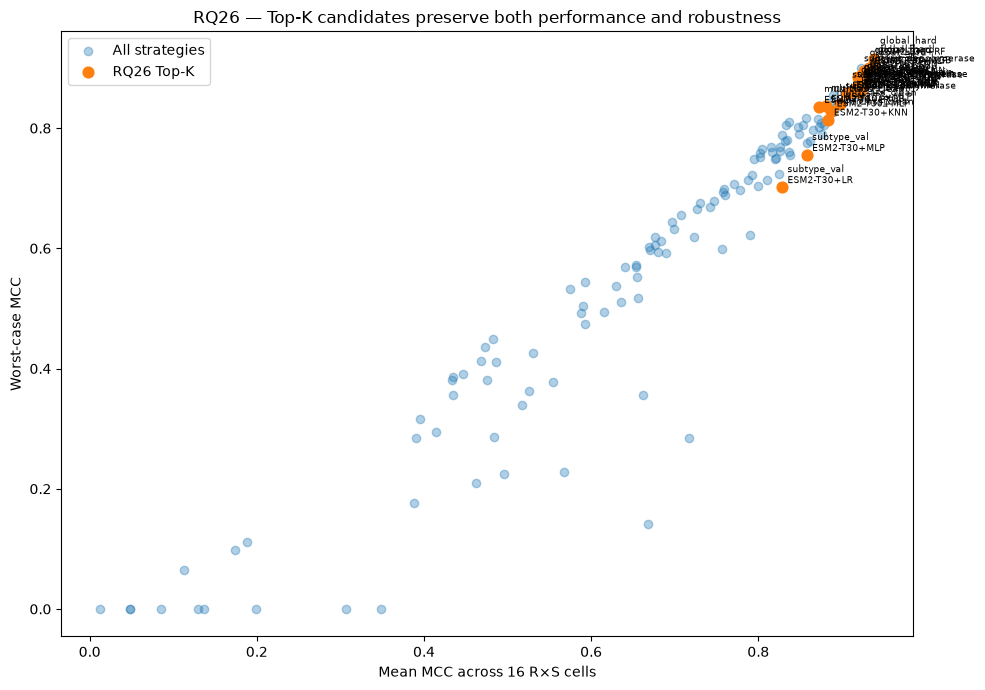

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_deployment/rq26/figures/rq26_topK_mean_vs_worst.png


In [12]:

# Figure 1 — all strategies: mean versus worst-case MCC; Top-K annotated.
fig, ax = plt.subplots(figsize=(10.0, 7.0))

ax.scatter(
    profile["mean_mcc"],
    profile["worst_mcc"],
    alpha=0.35,
    label="All strategies",
)

ax.scatter(
    topk["mean_mcc"],
    topk["worst_mcc"],
    s=60,
    label="RQ26 Top-K",
)

for row in topk.itertuples(index=False):
    ax.annotate(
        f"{row.task}\n{REP_LABEL.get(row.representation, row.representation)}+{row.algorithm}",
        (row.mean_mcc, row.worst_mcc),
        xytext=(4, 3),
        textcoords="offset points",
        fontsize=6.5,
    )

ax.set_xlabel("Mean MCC across 16 R×S cells")
ax.set_ylabel("Worst-case MCC")
ax.set_title("RQ26 — Top-K candidates preserve both performance and robustness")
ax.legend()
fig.tight_layout()

path = FIG_DIR / "rq26_topK_mean_vs_worst.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


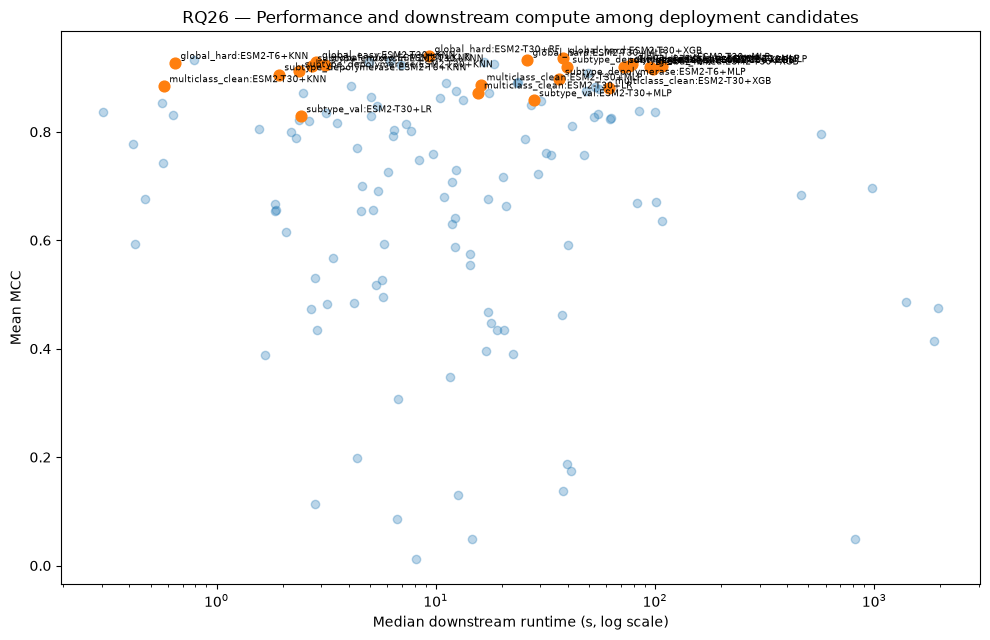

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_deployment/rq26/figures/rq26_topK_performance_vs_runtime.png


In [13]:

# Figure 2 — compute versus performance for selected models.
fig, ax = plt.subplots(figsize=(10.0, 6.5))

ax.scatter(
    profile["median_runtime_s"],
    profile["mean_mcc"],
    alpha=0.30,
)

ax.scatter(
    topk["median_runtime_s"],
    topk["mean_mcc"],
    s=60,
)

for row in topk.itertuples(index=False):
    ax.annotate(
        f"{row.task}:{REP_LABEL.get(row.representation, row.representation)}+{row.algorithm}",
        (row.median_runtime_s, row.mean_mcc),
        xytext=(4, 3),
        textcoords="offset points",
        fontsize=6.2,
    )

ax.set_xscale("log")
ax.set_xlabel("Median downstream runtime (s, log scale)")
ax.set_ylabel("Mean MCC")
ax.set_title("RQ26 — Performance and downstream compute among deployment candidates")
fig.tight_layout()

path = FIG_DIR / "rq26_topK_performance_vs_runtime.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


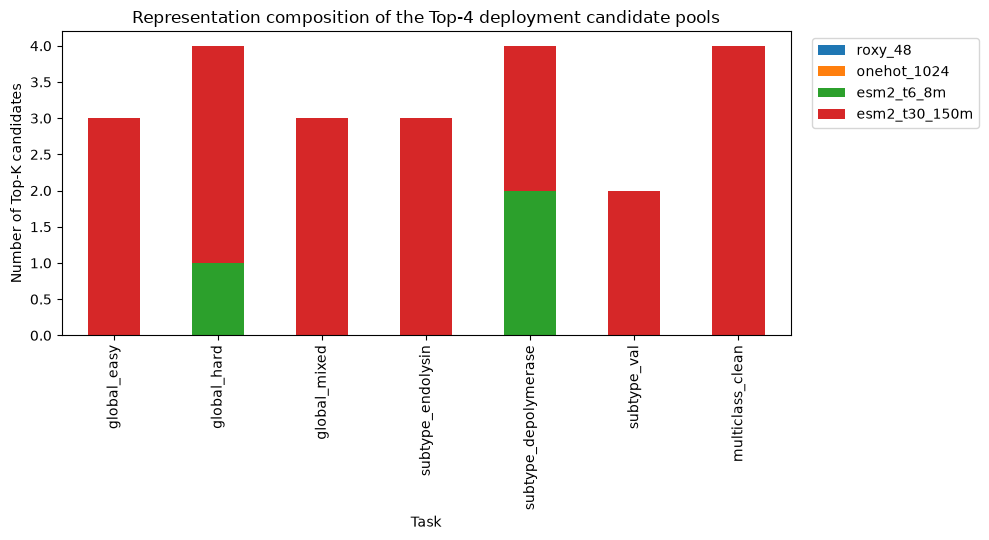

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_deployment/rq26/figures/rq26_topK_representation_composition.png


In [14]:

# Figure 3 — Top-K composition by representation.
rep_counts = (
    topk.groupby(["task", "representation"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=TASK_ORDER, columns=REP_ORDER, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10.0, 5.5))
rep_counts.plot(kind="bar", stacked=True, ax=ax)
ax.set_xlabel("Task")
ax.set_ylabel("Number of Top-K candidates")
ax.set_title("Representation composition of the Top-4 deployment candidate pools")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()

path = FIG_DIR / "rq26_topK_representation_composition.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


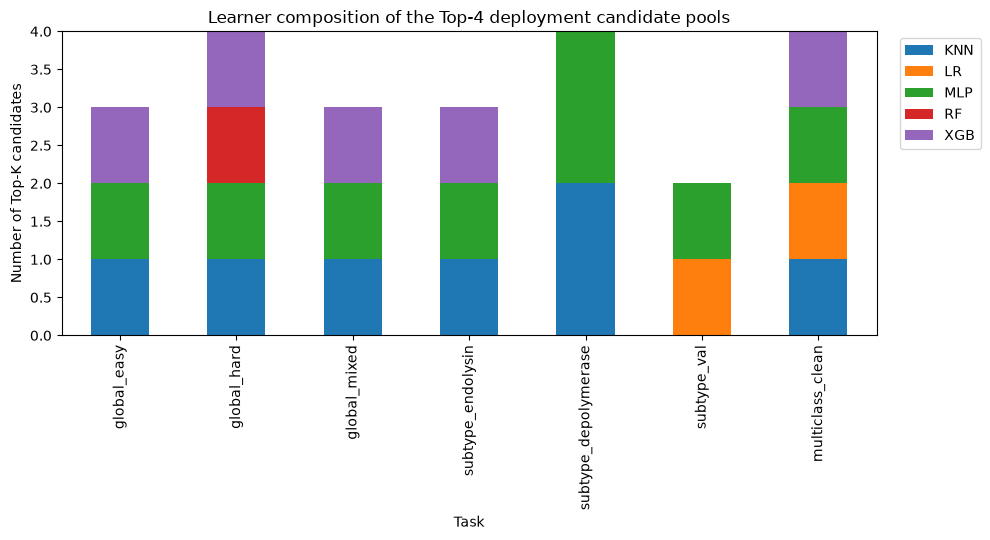

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_deployment/rq26/figures/rq26_topK_algorithm_composition.png


In [15]:

# Figure 4 — Top-K composition by learner.
alg_counts = (
    topk.groupby(["task", "algorithm"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=TASK_ORDER, columns=ALG_ORDER, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10.0, 5.5))
alg_counts.plot(kind="bar", stacked=True, ax=ax)
ax.set_xlabel("Task")
ax.set_ylabel("Number of Top-K candidates")
ax.set_title("Learner composition of the Top-4 deployment candidate pools")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()

path = FIG_DIR / "rq26_topK_algorithm_composition.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


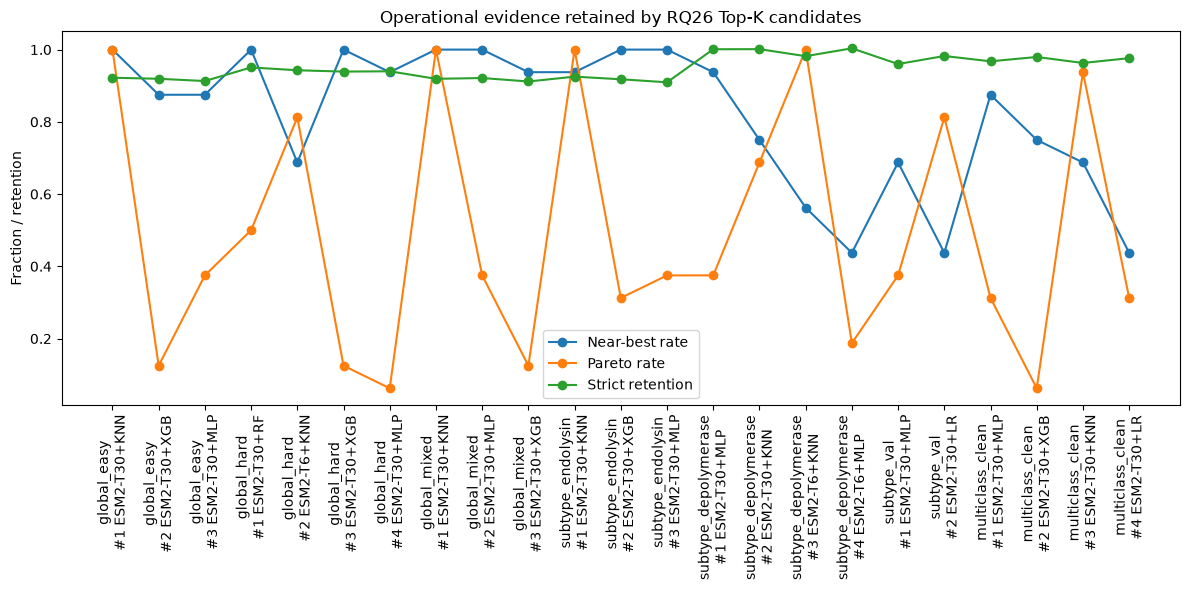

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_deployment/rq26/figures/rq26_topK_operational_evidence.png


In [16]:

# Figure 5 — selected members' operational evidence by task.
plot_rows = []
for row in topk.itertuples(index=False):
    plot_rows.append({
        "label": f"{row.task}\n#{row.topK_rank} {REP_LABEL.get(row.representation, row.representation)}+{row.algorithm}",
        "near_best_rate": row.near_best_rate,
        "pareto_rate": row.pareto_rate,
        "strict_retention_fraction": row.strict_retention_fraction,
    })

plot_df = pd.DataFrame(plot_rows)

fig, ax = plt.subplots(figsize=(12.0, 6.0))
x = np.arange(len(plot_df))
ax.plot(x, plot_df["near_best_rate"], marker="o", label="Near-best rate")
ax.plot(x, plot_df["pareto_rate"], marker="o", label="Pareto rate")
ax.plot(x, plot_df["strict_retention_fraction"], marker="o", label="Strict retention")
ax.set_xticks(x, plot_df["label"], rotation=90)
ax.set_ylabel("Fraction / retention")
ax.set_title("Operational evidence retained by RQ26 Top-K candidates")
ax.legend()
fig.tight_layout()

path = FIG_DIR / "rq26_topK_operational_evidence.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)



## 12. Scientific interpretation guardrails

RQ26 should answer:

1. Does the same individual strategy dominate performance, worst-case robustness, strict generalization, and compute?
2. When role winners differ, which strategies form the smallest defensible individual-model portfolio?
3. Does T30 occupy most Top-K slots, or do T6/simple learners survive because they are computationally competitive?
4. Which tasks preserve algorithm diversity despite representation convergence?
5. Is VAL's Top-K interpretation limited by finite-test uncertainty?
6. Which exact four members should RQ27 ensemble within each task?

### What RQ26 does not do

- It does not decide whether `global_easy`, `global_hard`, or `global_mixed` becomes the production global endpoint.
- It does not decide whether subtype binaries are core or auxiliary outputs.
- It does not optimize ensemble weights.
- It does not claim unbiased final-test performance for the selected Top-K.
- It does not manufacture an uncertainty score for models lacking targeted bootstrap coverage.
- It does not sum representation-extraction time into every downstream model runtime.

### Expected endpoint of RQ26

A valid RQ26 conclusion should look like:

> **The benchmark does not support a single universal individual winner. Instead, each endpoint can be reduced to a small evidence-supported candidate portfolio that preserves the strongest observed evidence for average performance, adverse-regime robustness, strict generalization, and computational practicality. These frozen portfolios define the individual models eligible for RQ27 ensemble testing. Portfolio size is allowed to vary between two and four members when the evidence does not justify a fourth standalone candidate.**


## 13. Export canonical RQ26 artifacts

In [17]:

exports = {
    "rq26_complete_candidate_profiles.tsv": profile,
    "rq26_operational_role_winners.tsv": role_winners,
    "rq26_topK_individual_candidates.tsv": topk,
    "rq26_selection_audit.tsv": selection_audit,
    "rq26_portfolio_coverage.tsv": portfolio_coverage,
    "rq26_uncertainty_context.tsv": unc_context,
    "rq26_RQ27_candidate_manifest.tsv": rq27_manifest,
    "rq26_preflight.tsv": preflight,
}

for filename, df in exports.items():
    path = RQ26_OUT / filename
    df.to_csv(path, sep="\t", index=False)
    print(f"Wrote {filename}: {len(df)} rows")

manifest = {
    "rq": "RQ26",
    "question": "which individual Top-K models should advance toward deployment?",
    "max_k": MAX_K,
    "min_k": MIN_K,
    "competitive_mean_mcc_gap": COMPETITIVE_GAP,
    "selection_type": "multi-role portfolio; no scalar deployment score",
    "primary_roles": PRIMARY_ROLE_ORDER,
    "fallback_roles": FALLBACK_ROLE_ORDER,
    "n_tasks": int(topk["task"].nunique()),
    "n_complete_candidate_profiles": int(len(profile)),
    "n_selected_candidates": int(len(topk)),
    "selected_k_by_task": {k: int(v) for k, v in topk.groupby("task").size().to_dict().items()},
    "selection_eligibility": "wins explicit role OR mean MCC within 0.02 of task best; non-competitive role-free fills are prohibited except explicit MIN_K technical fallback",
    "uncertainty_policy": (
        "targeted scientific RQ19 bootstrap is attached as context only; "
        "missing targeted coverage is not penalized"
    ),
    "compute_policy": (
        "downstream runtime only; representation extraction remains separate/amortizable"
    ),
    "evaluation_policy": (
        "retrospective outer-test benchmark synthesis; not a new independent final test"
    ),
    "training_performed": False,
    "prediction_regeneration_performed": False,
    "bootstrap_performed": False,
    "ensemble_optimization_performed": False,
}

with open(RQ26_OUT / "rq26_manifest.json", "w", encoding="utf-8") as fh:
    json.dump(manifest, fh, indent=2)

print("Wrote rq26_manifest.json")


Wrote rq26_complete_candidate_profiles.tsv: 140 rows
Wrote rq26_operational_role_winners.tsv: 63 rows
Wrote rq26_topK_individual_candidates.tsv: 23 rows
Wrote rq26_selection_audit.tsv: 140 rows
Wrote rq26_portfolio_coverage.tsv: 7 rows
Wrote rq26_uncertainty_context.tsv: 140 rows
Wrote rq26_RQ27_candidate_manifest.tsv: 23 rows
Wrote rq26_preflight.tsv: 7 rows
Wrote rq26_manifest.json


## 14. Execution gates

In [18]:

required_exports = [
    *exports.keys(),
    "rq26_manifest.json",
]

assert len(master) == 2240
assert len(profile) == 140
assert profile.groupby("task").size().eq(20).all()

assert "strict_retention_fraction" in profile.columns
assert not any(
    c.startswith("strict_retention_fraction_")
    for c in profile.columns
)
assert max_retention_diff <= 1e-10

assert len(role_winners) == len(TASK_ORDER) * 9
assert role_winners.groupby("task").size().eq(9).all()

assert topk.groupby("task").size().between(MIN_K, MAX_K).all()
assert topk.groupby(["task", "strategy_id"]).size().eq(1).all()
assert topk["topK_rank"].ge(1).all()
assert topk["topK_rank"].le(MAX_K).all()

bad_selected = selection_audit[
    selection_audit["selected"]
    & ~selection_audit["portfolio_eligible"]
].copy()

technical_keys = set(
    topk.loc[
        topk["selection_entry_reason"].eq("minimum_ensembleability_fill"),
        ["task", "strategy_id"],
    ].itertuples(index=False, name=None)
)

if len(bad_selected):
    bad_nontechnical = bad_selected[
        ~bad_selected.apply(
            lambda r: (r["task"], r["strategy_id"]) in technical_keys,
            axis=1,
        )
    ]
    assert len(bad_nontechnical) == 0, (
        "Non-competitive role-free models entered the portfolio:\n"
        + bad_nontechnical.to_string(index=False)
    )

assert portfolio_coverage["best_mean_mcc_topK"].eq(
    portfolio_coverage["best_mean_mcc_all"]
).all()

assert np.allclose(
    portfolio_coverage["best_worst_mcc_topK"],
    portfolio_coverage["best_worst_mcc_all"],
    atol=1e-12,
    rtol=0,
)
assert np.allclose(
    portfolio_coverage["best_strict_mcc_topK"],
    portfolio_coverage["best_strict_mcc_all"],
    atol=1e-12,
    rtol=0,
)
assert portfolio_coverage["all_primary_roles_represented"].all()

assert all((RQ26_OUT / f).is_file() for f in required_exports)

figure_files = sorted(p.name for p in FIG_DIR.glob("*.png"))
assert len(figure_files) >= 5

k_counts = topk.groupby("task").size().reindex(TASK_ORDER)
expected_ensembles = (2 ** k_counts) - k_counts - 1

print("RQ26_EXECUTION_GATES_OK")
print("Candidate profiles:", len(profile))
print("Operational role winners:", len(role_winners))
print("Selected deployment candidates:", len(topk))
print("Tasks:", topk["task"].nunique())
print("K by task:")
print(k_counts.to_string())
print("Expected RQ27 non-singleton ensembles by task:")
print(expected_ensembles.to_string())
print("Total expected RQ27 ensembles:", int(expected_ensembles.sum()))
print("Technical MIN_K fills:", int(
    topk["selection_entry_reason"].eq("minimum_ensembleability_fill").sum()
))
print("Exports:", len(required_exports))
print("Figures:", figure_files)
print()
print(
    "Interpretation status: execution gates passed. "
    "Assign REAL-DATA PASS only after the executed notebook and outputs are inspected."
)


RQ26_EXECUTION_GATES_OK
Candidate profiles: 140
Operational role winners: 63
Selected deployment candidates: 23
Tasks: 7
K by task:
task
global_easy             3
global_hard             4
global_mixed            3
subtype_endolysin       3
subtype_depolymerase    4
subtype_val             2
multiclass_clean        4
Expected RQ27 non-singleton ensembles by task:
task
global_easy              4
global_hard             11
global_mixed             4
subtype_endolysin        4
subtype_depolymerase    11
subtype_val              1
multiclass_clean        11
Total expected RQ27 ensembles: 46
Technical MIN_K fills: 0
Exports: 9
Figures: ['rq26_topK_algorithm_composition.png', 'rq26_topK_mean_vs_worst.png', 'rq26_topK_operational_evidence.png', 'rq26_topK_performance_vs_runtime.png', 'rq26_topK_representation_composition.png']

Interpretation status: execution gates passed. Assign REAL-DATA PASS only after the executed notebook and outputs are inspected.
